# FedVocabHAR RealWorld HAR Phase 3D

## Selection-only redesign of agreement-triggered vocabulary growth

Phase 3C showed that connected-component agreement saved label queries but merged distinct novel activities too aggressively. Phase 3D develops a replacement policy without accessing any test-subject window or label. It compares three fixed policies on selection-subject streams: legacy connected components, mutual-nearest-neighbor agreement, and mutual-nearest-neighbor agreement with ranked candidate retention.

The selected policy is exploratory and must be locked before a third-dataset confirmatory experiment.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
import json,random,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score,normalized_mutual_info_score,precision_recall_fscore_support

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    seed:int=42
    known_activities:tuple=('walking','running','sitting','standing')
    novel_activities:tuple=('climbingup','climbingdown','jumping','lying')
    probe_per_subject_activity:int=220
    max_candidates_per_client:int=600
    min_local_cluster_size:int=12
    min_agreeing_clients:int=2
    label_query_budget:int=4
    novelty_false_alarm_quantile:float=.02
    local_distance_quantile:float=.90
    agreement_similarity_quantile:float=.10
    selection_score_recovery_weight:float=.50
    selection_score_purity_weight:float=.30
    selection_score_novel_f1_weight:float=.20
    selection_score_query_penalty:float=.05

CFG=Config();PROJECT=Path(CFG.project);P3A=PROJECT/'artifacts'/'phase3a';P3B=PROJECT/'artifacts'/'phase3b';OUT=PROJECT/'artifacts'/'phase3d';FOLD_DIR=OUT/'folds'
OUT.mkdir(parents=True,exist_ok=True);FOLD_DIR.mkdir(parents=True,exist_ok=True)
CACHE=PROJECT/'data'/'realworld'/'cache'/'realworld_forearm_acc_w128_s64_50hz.npz';MANIFEST=P3A/'phase3a_preregistered_manifest.json'
assert CACHE.exists() and MANIFEST.exists() and all((P3B/'folds'/f'fold_{i}_models.pt').exists() for i in range(1,6))
folds=json.loads(MANIFEST.read_text())['outer_folds'];DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_all(CFG.seed);print('device:',DEVICE);print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "known_activities": [
    "walking",
    "running",
    "sitting",
    "standing"
  ],
  "novel_activities": [
    "climbingup",
    "climbingdown",
    "jumping",
    "lying"
  ],
  "probe_per_subject_activity": 220,
  "max_candidates_per_client": 600,
  "min_local_cluster_size": 12,
  "min_agreeing_clients": 2,
  "label_query_budget": 4,
  "novelty_false_alarm_quantile": 0.02,
  "local_distance_quantile": 0.9,
  "agreement_similarity_quantile": 0.1,
  "selection_score_recovery_weight": 0.5,
  "selection_score_purity_weight": 0.3,
  "selection_score_novel_f1_weight": 0.2,
  "selection_score_query_penalty": 0.05
}


## Frozen representations and selection-only protocol

For a fold, encoder-training subjects supply known prototypes. Selection subjects provide mixed unlabeled streams to local discovery. Their labels are hidden from every discovery, matching, promotion, and query decision; they are revealed only to calculate the validation metrics that select one policy. The three test subjects are explicitly excluded.


In [3]:
d=np.load(CACHE);x=d['x'].astype(np.float32);subjects=d['subject'].astype(int);activities=d['activity'].astype(str)
all_activities=CFG.known_activities+CFG.novel_activities;known_to_index={a:i for i,a in enumerate(CFG.known_activities)}

class InceptionBlock(nn.Module):
    def __init__(self,cin,width=32):
        super().__init__();self.bottleneck=nn.Conv1d(cin,width,1,bias=False);self.branches=nn.ModuleList([nn.Conv1d(width,width,k,padding=k//2,bias=False) for k in (9,19,39)]);self.pool=nn.Sequential(nn.MaxPool1d(3,stride=1,padding=1),nn.Conv1d(cin,width,1,bias=False));self.bn=nn.BatchNorm1d(width*4)
    def forward(self,q):z=self.bottleneck(q);return F.relu(self.bn(torch.cat([b(z) for b in self.branches]+[self.pool(q)],1)))
class InceptionEncoder(nn.Module):
    def __init__(self):
        super().__init__();self.block1=InceptionBlock(4,32);self.block2=InceptionBlock(128,32);self.skip=nn.Conv1d(4,128,1,bias=False);self.bn=nn.BatchNorm1d(128);self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,64));self.decoder=nn.Conv1d(128,4,1);self.domain=nn.Sequential(nn.Linear(64,64),nn.ReLU(),nn.Linear(64,6))
    def forward(self,q):seq=F.relu(self.bn(self.block2(self.block1(q))+self.skip(q)));return F.normalize(self.project(seq.mean(-1)),dim=1)
def load(path):
    try:return torch.load(path,map_location='cpu',weights_only=False)
    except TypeError:return torch.load(path,map_location='cpu')
def encode(model,data,batch=512):
    out=[];model.eval()
    with torch.no_grad():
        for i in range(0,len(data),batch):out.append(model(torch.from_numpy(data[i:i+batch]).to(DEVICE)).cpu().numpy())
    return np.concatenate(out)
def unit(z):return z/(np.linalg.norm(z,axis=1,keepdims=True)+1e-12)
def limited(subject_set,activity_set,n,seed):
    rng=np.random.default_rng(seed);out=[]
    for s in subject_set:
        for a in activity_set:
            q=np.where((subjects==s)&(activities==a))[0]
            if len(q)>n:q=rng.choice(q,n,replace=False)
            out+=q.tolist()
    return np.asarray(out,dtype=int)
def embedding_for_fold(fold_id):
    bundle=load(P3B/'folds'/f'fold_{fold_id}_models.pt');st=bundle['stats'];inp=np.concatenate([(x[:,:3]-st['xyz_mean'])/st['xyz_std'],(x[:,3:4]-st['mag_mean'])/st['mag_std']],1).astype(np.float32);m=InceptionEncoder().to(DEVICE);m.load_state_dict(bundle['anchor_state_dict']);return unit(encode(m,inp))
def calibration(emb,fold):
    train=tuple(fold['train_subjects']);sel=tuple(fold['selection_subjects']);tr=limited(train,CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+10*fold['fold']);se=limited(sel,CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+10*fold['fold']+1);y=np.asarray([known_to_index[a] for a in activities[tr]]);p=np.asarray([unit(emb[tr][y==k].mean(0,keepdims=True))[0] for k in range(4)]);truth=np.asarray([known_to_index[a] for a in activities[se]]);score=emb[se]@p.T;novelty=float(np.quantile(score[np.arange(len(score)),truth],CFG.novelty_false_alarm_quantile));within=[];cross=[];rng=np.random.default_rng(CFG.seed+fold['fold'])
    for a in CFG.known_activities:
        means=[]
        for s in sel:
            q=np.where((subjects==s)&(activities==a))[0];q=rng.choice(q,min(80,len(q)),replace=False);z=emb[q];within += (1-z@z.T)[np.triu_indices(len(z),1)].tolist()
        for s in train:
            q=np.where((subjects==s)&(activities==a))[0];means.append(unit(emb[q].mean(0,keepdims=True))[0])
        cross += [float(means[i]@means[j]) for i in range(len(means)) for j in range(i+1,len(means))]
    return p,{'novelty_threshold':novelty,'local_distance':float(np.quantile(within,CFG.local_distance_quantile)),'agreement_similarity':float(np.quantile(cross,CFG.agreement_similarity_quantile))}


## Local candidate policies and agreement policies

`threshold_component` reproduces the Phase 3C merge rule. `threshold_mnn` replaces transitive components with mutual nearest-neighbor cross-client matches. `ranked_mnn` always retains each client's most novel 600 windows before the same MNN matching, avoiding the zero-candidate failure of a hard global cutoff. All three use the identical local clustering, matching calibration, and four-query budget.


In [4]:
def cluster(z,d):
    if len(z)<2:return np.zeros(len(z),dtype=int)
    try:return AgglomerativeClustering(n_clusters=None,distance_threshold=d,metric='cosine',linkage='average').fit_predict(z)
    except TypeError:return AgglomerativeClustering(n_clusters=None,distance_threshold=d,affinity='cosine',linkage='average').fit_predict(z)
def local(emb,clients,p,c,ranked,seed):
    rng=np.random.default_rng(seed);rows=[];truth=[];assigned=[]
    for s in clients:
        idx=np.where(subjects==s)[0];nov=1-(emb[idx]@p.T).max(1)
        if ranked:q=idx[np.argsort(nov)[-min(CFG.max_candidates_per_client,len(idx)):]]
        else:q=idx[(emb[idx]@p.T).max(1)<c['novelty_threshold']];q=rng.choice(q,min(len(q),CFG.max_candidates_per_client),replace=False) if len(q)>CFG.max_candidates_per_client else q
        labels=cluster(emb[q],c['local_distance'])
        for lab in np.unique(labels):
            m=np.where(labels==lab)[0]
            if len(m)<CFG.min_local_cluster_size:continue
            w=q[m];sig=unit(emb[w].mean(0,keepdims=True))[0];med=w[np.argmax(emb[w]@sig)];v,n=np.unique(activities[w],return_counts=True)
            rows.append({'client':int(s),'signature':sig,'support':len(w),'medoid':int(med),'query_label':str(activities[med]),'dominant':str(v[np.argmax(n)]),'purity':float(n.max()/n.sum())});truth += activities[w].tolist();assigned += [f'{s}:{lab}']*len(w)
    return rows,np.asarray(truth),np.asarray(assigned)
def components(z,t):
    seen=set();out=[]
    for i in range(len(z)):
        if i in seen:continue
        todo=[i];seen.add(i);g=[]
        while todo:
            a=todo.pop();g.append(a)
            for b in np.where(z[a]@z.T>=t)[0]:
                if b not in seen:seen.add(int(b));todo.append(int(b))
        out.append(g)
    return out
def mnn_groups(rows,t):
    if not rows:return []
    z=np.asarray([r['signature'] for r in rows]);sim=z@z.T;best={}
    for i,r in enumerate(rows):
        eligible=[j for j,s in enumerate(rows) if s['client']!=r['client'] and sim[i,j]>=t]
        if eligible:best[i]=max(eligible,key=lambda j:sim[i,j])
    edges=[]
    for i,j in best.items():
        if best.get(j)==i:edges.append((i,j))
    groups=[];seen=set()
    for i,j in edges:
        key=tuple(sorted((i,j)))
        if key not in seen:groups.append(list(key));seen.add(key)
    return groups
def make_entries(rows,groups):
    candidates=[]
    for g in groups:
        members=[rows[i] for i in g];clients=set(r['client'] for r in members)
        if len(clients)<CFG.min_agreeing_clients:continue
        sig=unit(np.stack([r['signature'] for r in members]).mean(0,keepdims=True))[0];med=max(members,key=lambda r:sig@r['signature'])['medoid']
        candidates.append({'signature':sig,'label':str(activities[med]),'clients':clients,'support':sum(r['support'] for r in members),'purity':float(np.average([r['purity'] for r in members],weights=[r['support'] for r in members])),'dominant':[r['dominant'] for r in members]})
    queried=sorted(candidates,key=lambda r:r['support'],reverse=True)[:CFG.label_query_budget];accepted=[r for r in queried if r['label'] in CFG.novel_activities];dedup=[];seen=set()
    for r in accepted:
        if r['label'] not in seen:dedup.append(r);seen.add(r['label'])
    return dedup,len(queried)
def validation_score(emb,entries,known_idx,selection_idx):
    y=np.asarray([known_to_index[a] for a in activities[known_idx]]);kp=np.asarray([unit(emb[known_idx][y==k].mean(0,keepdims=True))[0] for k in range(4)]);labels=list(CFG.known_activities)+[r['label'] for r in entries];proto=np.asarray([*kp]+[r['signature'] for r in entries]);pred=np.asarray(labels)[(emb[selection_idx]@proto.T).argmax(1)];true=activities[selection_idx];f=precision_recall_fscore_support(true,pred,labels=list(all_activities),zero_division=0)[2];return float(f[4:].mean())


## Five-fold selection-only ablation and policy lock

Selection-subject novel labels are revealed only after entries are fixed to measure recovery, purity, and vocabulary classification. The locked selection score rewards novel recovery, entry purity, and novel F1, with a small query penalty. No test-subject index is created or accessed.


In [5]:
POLICIES={'threshold_component':{'ranked':False,'matching':'component'},'threshold_mnn':{'ranked':False,'matching':'mnn'},'ranked_mnn':{'ranked':True,'matching':'mnn'}}
for fold in folds:
    fid=int(fold['fold']);path=FOLD_DIR/f'fold_{fid}_complete.json'
    if path.exists():print('fold',fid,'already complete');continue
    test=set(fold['test_subjects']);train=tuple(fold['train_subjects']);sel=tuple(fold['selection_subjects']);assert test.isdisjoint(train) and test.isdisjoint(sel) and set(train).isdisjoint(sel)
    emb=embedding_for_fold(fid);p,c=calibration(emb,fold);known_idx=limited(train,CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+500+fid);selection_idx=np.where(np.isin(subjects,sel))[0];rows=[];entries_audit=[]
    for name,spec in POLICIES.items():
        signatures,truth,assigned=local(emb,sel,p,c,spec['ranked'],CFG.seed+fid);z=np.asarray([r['signature'] for r in signatures]) if signatures else np.empty((0,64));groups=components(z,c['agreement_similarity']) if spec['matching']=='component' else mnn_groups(signatures,c['agreement_similarity']);entries,queries=make_entries(signatures,groups);recovered=len(set(r['label'] for r in entries));purity=float(np.mean([r['purity'] for r in entries])) if entries else 0.;novel_f1=validation_score(emb,entries,known_idx,selection_idx);ari=float(adjusted_rand_score(truth,assigned)) if len(truth) else 0.;nmi=float(normalized_mutual_info_score(truth,assigned)) if len(truth) else 0.;score=CFG.selection_score_recovery_weight*(recovered/4)+CFG.selection_score_purity_weight*purity+CFG.selection_score_novel_f1_weight*novel_f1-CFG.selection_score_query_penalty*(queries/CFG.label_query_budget)
        rows.append({'fold':fid,'policy':name,'local_signatures':len(signatures),'agreement_groups':len(groups),'promoted_entries':len(entries),'label_queries':queries,'novel_recovery':recovered/4,'entry_purity':purity,'novel_macro_f1':novel_f1,'cluster_ari':ari,'cluster_nmi':nmi,'selection_score':score})
        for k,e in enumerate(entries,1):entries_audit.append({'fold':fid,'policy':name,'entry':k,'label':e['label'],'clients':','.join(map(str,sorted(e['clients']))),'support':e['support'],'purity':e['purity'],'dominant_labels':'|'.join(e['dominant'])})
    path.write_text(json.dumps({'fold':fold,'calibration':c,'results':rows,'entries':entries_audit},indent=2));print('completed fold',fid)


completed fold 1
completed fold 2
completed fold 3
completed fold 4
completed fold 5


,fold,policy,local_signatures,agreement_groups,promoted_entries,label_queries,novel_recovery,entry_purity,novel_macro_f1,cluster_ari,cluster_nmi,selection_score
0,1,threshold_component,0,0,0,0,0.00,0.0000,0.0000,0.0000,0.0000,0.0000
1,1,threshold_mnn,0,0,0,0,0.00,0.0000,0.0000,0.0000,0.0000,0.0000
2,1,ranked_mnn,23,8,3,4,0.75,0.7898,0.4504,0.2412,0.4521,0.6520
3,2,threshold_component,0,0,0,0,0.00,0.0000,0.0000,0.0000,0.0000,0.0000
4,2,threshold_mnn,0,0,0,0,0.00,0.0000,0.0000,0.0000,0.0000,0.0000
5,2,ranked_mnn,8,2,0,2,0.00,0.0000,0.0000,0.2120,0.3105,-0.0250
6,3,threshold_component,2,1,1,1,0.25,1.0000,0.1118,0.0000,0.0000,0.4349
7,3,threshold_mnn,2,1,1,1,0.25,1.0000,0.1118,0.0000,0.0000,0.4349
8,3,ranked_mnn,13,4,1,4,0.25,0.6515,0.1746,0.3726,0.5391,0.3054
9,4,threshold_component,3,1,1,1,0.25,0.9324,0.1195,0.2610,0.4094,0.4161


{
  "phase": "Phase 3D",
  "status": "Selection-only exploratory redesign; no test-subject windows or labels were accessed.",
  "selected_policy": "ranked_mnn",
  "selection_summary": {
    "ranked_mnn": {
      "fold": 3.0,
      "local_signatures": 13.2,
      "agreement_groups": 4.4,
      "promoted_entries": 1.6,
      "label_queries": 3.6,
      "novel_recovery": 0.4,
      "entry_purity": 0.6197860019,
      "novel_macro_f1": 0.2460143858,
      "cluster_ari": 0.2772475587,
      "cluster_nmi": 0.4340307163,
      "selection_score": 0.3901386777
    },
    "threshold_component": {
      "fold": 3.0,
      "local_signatures": 1.0,
      "agreement_groups": 0.4,
      "promoted_entries": 0.4,
      "label_queries": 0.4,
      "novel_recovery": 0.1,
      "entry_purity": 0.3864864865,
      "novel_macro_f1": 0.046249449,
      "cluster_ari": 0.0521975574,
      "cluster_nmi": 0.0818857855,
      "selection_score": 0.1701958357
    },
    "threshold_mnn": {
      "fold": 3.0,
      "

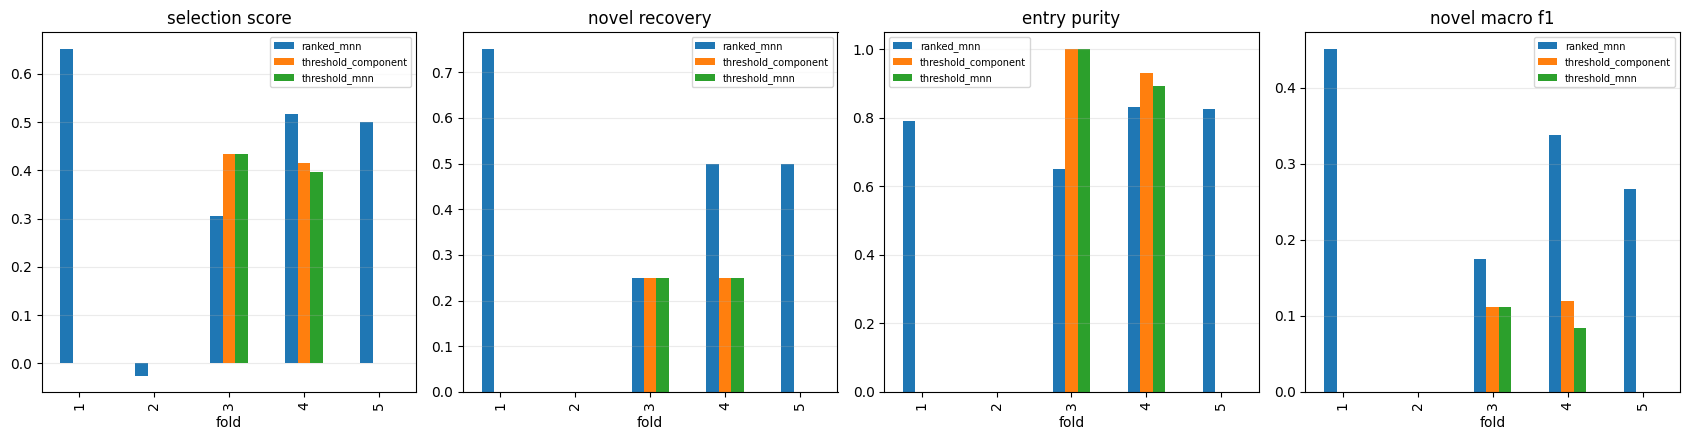

# FedVocabHAR Phase 3D Policy Lock

**Selected policy:** ranked_mnn

This selection used only encoder-training and selection-subject data. The next evaluation must use a third dataset with an unopened test split.

## ranked_mnn

- Selection score: 0.3901
- Novel recovery: 0.4000
- Entry purity: 0.6198
- Novel macro-F1: 0.2460
- Label queries: 3.60

## threshold_component

- Selection score: 0.1702
- Novel recovery: 0.1000
- Entry purity: 0.3865
- Novel macro-F1: 0.0462
- Label queries: 0.40

## threshold_mnn

- Selection score: 0.1664
- Novel recovery: 0.1000
- Entry purity: 0.3785
- Novel macro-F1: 0.0392
- Label queries: 0.40




In [6]:
assert all((FOLD_DIR/f'fold_{i}_complete.json').exists() for i in range(1,6)),'Rerun the prior cell until all folds complete'
payloads=[json.loads((FOLD_DIR/f'fold_{i}_complete.json').read_text()) for i in range(1,6)];results=pd.DataFrame([r for p in payloads for r in p['results']]);entries=pd.DataFrame([r for p in payloads for r in p['entries']]);cal=pd.DataFrame([{'fold':p['fold']['fold'],**p['calibration']} for p in payloads]);results.to_csv(OUT/'phase3d_selection_results.csv',index=False);entries.to_csv(OUT/'phase3d_promoted_entries.csv',index=False);cal.to_csv(OUT/'phase3d_calibration.csv',index=False)
summary=results.groupby('policy').mean(numeric_only=True).sort_values('selection_score',ascending=False);winner=str(summary.index[0]);decision={'phase':'Phase 3D','status':'Selection-only exploratory redesign; no test-subject windows or labels were accessed.','selected_policy':winner,'selection_summary':json.loads(summary.to_json(orient='index')),'policy':POLICIES[winner],'locked_for_third_dataset':True,'config':asdict(CFG)};(OUT/'phase3d_policy_lock.json').write_text(json.dumps(decision,indent=2));display(results.round(4));print(json.dumps(decision,indent=2))
fig,axes=plt.subplots(1,4,figsize=(17,4.5))
for ax,metric in zip(axes,['selection_score','novel_recovery','entry_purity','novel_macro_f1']):
    results.pivot(index='fold',columns='policy',values=metric).plot(kind='bar',ax=ax);ax.set_title(metric.replace('_',' '));ax.grid(axis='y',alpha=.25);ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(OUT/'phase3d_policy_comparison.png',dpi=180,bbox_inches='tight');plt.show()
report=f"# FedVocabHAR Phase 3D Policy Lock\n\n**Selected policy:** {winner}\n\nThis selection used only encoder-training and selection-subject data. The next evaluation must use a third dataset with an unopened test split.\n\n"
for policy,row in summary.iterrows():report+=f"## {policy}\n\n- Selection score: {row.selection_score:.4f}\n- Novel recovery: {row.novel_recovery:.4f}\n- Entry purity: {row.entry_purity:.4f}\n- Novel macro-F1: {row.novel_macro_f1:.4f}\n- Label queries: {row.label_queries:.2f}\n\n"
(OUT/'FedVocabHAR_Phase3D_Policy_Lock.md').write_text(report);print(report)


## Next step

The selected policy, encoder architecture, calibration quantiles, and label-query budget are now locked. Prepare a third-dataset confirmatory experiment; do not use RealWorld test-subject results to make any further Phase 3D choice.
